In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from study_config import *

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

d = pd.read_csv(PROC / "retail_clean_flagged.csv", parse_dates=["date"])
d["t"] = (d["date"].dt.year - 2016) * 12 + d["date"].dt.month - 1        # month counter, Jan 2016 = 0
T0 = (2020 - 2016) * 12 + 4                                              # May 2020
PRE_MIN, PAN_MIN, FLAT_N = 24, 12, 6      # >= 24 pre months, >= 12 pandemic months; "flat" = mean of last 6 pre months
ids = ["market_id", "commodity_id", "category", "commodity", "market", "admin1"]

In [2]:
npre = d[d["period"] == "Pre-pandemic"].groupby(ids).size().rename("n_pre")
npan = d[d["period"] == "Pandemic"].groupby(ids).size().rename("n_pan")
S = pd.concat([npre, npan], axis=1).dropna().reset_index()
E = S[(S["n_pre"] >= PRE_MIN) & (S["n_pan"] >= PAN_MIN)].copy()
print("Series observed in both periods:", len(S), "| at least 6 months in each (Step 10 rule):",
      int(((S["n_pre"] >= 6) & (S["n_pan"] >= 6)).sum()), "| main rule here:", len(E))
print("By market:", E.groupby("market").size().to_dict())
print("Commodities:", E["commodity"].nunique(), "| by category:", E["category"].value_counts().to_dict())

Series observed in both periods: 41 | at least 6 months in each (Step 10 rule): 38 | main rule here: 26
By market: {'Davao City': 6, 'Metro Manila': 9, 'Zamboanga City': 11}
Commodities: 13 | by category: {'meat, fish and eggs': 10, 'vegetables and fruits': 8, 'cereals and tubers': 6, 'pulses and nuts': 2}


In [3]:
def counterfactual(s):
    sp, sn = s[s["period"] == "Pre-pandemic"].sort_values("t"), s[s["period"] == "Pandemic"].sort_values("t")
    t, y = sp["t"].to_numpy(float), sp["log_price"].to_numpy()
    n = len(t)
    X = np.c_[np.ones(n), t]
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    s2 = ((y - X @ b) ** 2).sum() / (n - 2)
    XtXi = np.linalg.inv(X.T @ X)
    tn = sn["t"].to_numpy(float)
    Xn = np.c_[np.ones(len(tn)), tn]
    pred = Xn @ b
    half = stats.t.ppf(0.975, n - 2) * np.sqrt(s2 * (1 + np.einsum("ij,jk,ik->i", Xn, XtXi, Xn)))
    flat = y[-FLAT_N:].mean()
    return t, y, tn, sn["log_price"].to_numpy(), pred, half, flat

rows = []
for r in E.itertuples(index=False):
    s = d[(d["market_id"] == r.market_id) & (d["commodity_id"] == r.commodity_id)]
    t, y, tn, yo, pred, half, flat = counterfactual(s)
    for a, b_, c_, d_ in zip(tn, yo, pred, half):
        rows.append((r.market, r.commodity, r.category, r.market_id, r.commodity_id, a, b_, c_, flat, d_,
                     int((a - T0) // 12 + 1)))
C = pd.DataFrame(rows, columns=["market", "commodity", "category", "market_id", "commodity_id", "t", "y",
                                "trend", "flat", "pi", "pandemic_year"])
C["ex_trend"], C["ex_flat"] = C["y"] - C["trend"], C["y"] - C["flat"]
C["outside_pi"] = C["ex_trend"].abs() > C["pi"]
pct = lambda x: (np.exp(x) - 1) * 100
print("Observations:", len(C), "| series:", C.groupby(["market_id", "commodity_id"]).ngroups)

Observations: 560 | series: 26


In [4]:
print("How well does the pre-pandemic trend interval hold up?")
print("Share of pandemic observations outside the 95% interval:", round(C["outside_pi"].mean() * 100, 1),
      "| above:", round((C["ex_trend"] > C["pi"]).mean() * 100, 1), "| below:", round((C["ex_trend"] < -C["pi"]).mean() * 100, 1))
print("By pandemic year:", C.groupby("pandemic_year")["outside_pi"].mean().mul(100).round(1).to_dict())

ser_year = (C.groupby(["market_id", "commodity_id", "commodity", "market", "pandemic_year"])
              .agg(ex_trend=("ex_trend", "mean"), ex_flat=("ex_flat", "mean")).reset_index())
w = (C.groupby(["market_id", "commodity_id", "commodity", "market", "category"])
       .agg(ex_trend=("ex_trend", "mean"), ex_flat=("ex_flat", "mean")).reset_index())
print("\nWhole pandemic period, median excess over each counterfactual (%):",
      "trend", round(pct(w["ex_trend"].median()), 1), "| flat", round(pct(w["ex_flat"].median()), 1))
print("Share of series above trend:", round((w["ex_trend"] > 0).mean() * 100, 1),
      "% | above flat:", round((w["ex_flat"] > 0).mean() * 100, 1), "%")
wn = w[~w["commodity"].str.startswith("Onions")]
print("Without onions (", len(wn), "series ): trend", round(pct(wn["ex_trend"].median()), 1),
      "| flat", round(pct(wn["ex_flat"].median()), 1))

full = C.groupby(["market_id", "commodity_id"])["pandemic_year"].nunique()
full = full[full == 4].index
sf = ser_year.set_index(["market_id", "commodity_id"]).loc[list(full)].reset_index()
agg_year = lambda df: df.groupby("pandemic_year").agg(series=("ex_trend", "size"),
                          vs_trend=("ex_trend", lambda x: pct(x.median())),
                          vs_flat=("ex_flat", lambda x: pct(x.median()))).round(1)
print("\nTime path, only the", len(full), "series observed in all four pandemic years (median excess %):")
display(agg_year(sf))
print("Time path, all series (composition changes by year):")
display(agg_year(ser_year))
print("Median half-width of the trend interval (%):",
      C.groupby("pandemic_year")["pi"].apply(lambda x: pct(x.median())).round(1).to_dict())

bc = (w.groupby("commodity").agg(series=("ex_flat", "size"), vs_trend=("ex_trend", lambda x: pct(x.median())),
                                 vs_flat=("ex_flat", lambda x: pct(x.median()))).round(1).sort_values("vs_flat"))
print("\nBy commodity (median across series, %):"); display(bc)
bm = (w.groupby("market").agg(series=("ex_flat", "size"), vs_trend=("ex_trend", lambda x: pct(x.median())),
                              vs_flat=("ex_flat", lambda x: pct(x.median()))).round(1))
print("By market:"); display(bm)

res_ac = []
for r in E.itertuples(index=False):
    sp = d[(d["market_id"] == r.market_id) & (d["commodity_id"] == r.commodity_id)
           & (d["period"] == "Pre-pandemic")].sort_values("t")
    X = np.c_[np.ones(len(sp)), sp["t"].to_numpy(float)]
    e = sp["log_price"].to_numpy() - X @ np.linalg.lstsq(X, sp["log_price"].to_numpy(), rcond=None)[0]
    res_ac.append(np.corrcoef(e[:-1], e[1:])[0, 1])
print("\nMedian lag-1 autocorrelation of pre-pandemic trend residuals:", round(float(np.median(res_ac)), 2))

How well does the pre-pandemic trend interval hold up?
Share of pandemic observations outside the 95% interval: 60.2 | above: 46.6 | below: 13.6
By pandemic year: {1: 42.6, 2: 56.0, 3: 64.7, 4: 69.2}

Whole pandemic period, median excess over each counterfactual (%): trend 13.9 | flat 43.4
Share of series above trend: 73.1 % | above flat: 88.5 %
Without onions ( 22 series ): trend 13.2 | flat 38.1

Time path, only the 9 series observed in all four pandemic years (median excess %):


,series,vs_trend,vs_flat
pandemic_year,,,
1,9,13.4,20.9
2,9,11.2,18.6
3,9,8.3,33.0
4,9,16.8,30.9


Time path, all series (composition changes by year):


,series,vs_trend,vs_flat
pandemic_year,,,
1,9,13.4,20.9
2,26,11.4,29.2
3,26,18.7,47.9
4,26,18.6,53.6


Median half-width of the trend interval (%): {1: 12.4, 2: 14.9, 3: 18.1, 4: 19.5}

By commodity (median across series, %):


,series,vs_trend,vs_flat
commodity,,,
"Rice (regular, milled)",3,-18.1,-1.2
Eggs,1,-2.1,4.4
Garlic,1,11.1,8.9
Beans (mung),2,11.6,13.4
"Meat (chicken, whole)",3,14.1,28.0
Potatoes (Irish),3,37.0,43.9
Meat (pork),3,13.1,46.3
"Meat (beef, chops with bones)",3,-5.3,49.8
Carrots,1,95.5,60.8


By market:


,series,vs_trend,vs_flat
market,,,
Davao City,6,13.8,48.1
Metro Manila,9,13.8,25.3
Zamboanga City,11,37.0,43.9



Median lag-1 autocorrelation of pre-pandemic trend residuals: 0.63


In [5]:
def hac_wald(X, y, L=4):
    n, k = X.shape
    XtXi = np.linalg.inv(X.T @ X)
    b = XtXi @ X.T @ y
    Xe = X * (y - X @ b)[:, None]
    S0 = Xe.T @ Xe
    for l in range(1, L + 1):
        G = Xe[l:].T @ Xe[:-l]
        S0 += (1 - l / (L + 1)) * (G + G.T)
    return b, XtXi @ S0 @ XtXi * (n / (n - k))

brk = []
for r in E.itertuples(index=False):
    s = d[(d["market_id"] == r.market_id) & (d["commodity_id"] == r.commodity_id)
          & d["period"].isin(["Pre-pandemic", "Pandemic"])].sort_values("t")
    ta, ya = s["t"].to_numpy(float), s["log_price"].to_numpy()
    D = (ta >= T0).astype(float)
    b, V = hac_wald(np.c_[np.ones(len(ta)), ta, D, D * (ta - T0)], ya)
    W = b[2:] @ np.linalg.inv(V[2:, 2:]) @ b[2:]
    brk.append((r.market, r.commodity, r.category, b[2], b[3] * 12, 1 - stats.chi2.cdf(W, 2)))
B = pd.DataFrame(brk, columns=["market", "commodity", "category", "level_shift", "slope_change_per_year", "p_value"])
print("Series tested:", len(B), "| no-break rejected at 5%:", int((B["p_value"] < 0.05).sum()),
      "| at 1%:", int((B["p_value"] < 0.01).sum()))
print("Median level shift at May 2020 (%):", round(pct(B["level_shift"].median()), 1),
      "| median slope change (percentage points per year):", round(pct(B["slope_change_per_year"].median()), 1))
display(B.groupby("category").agg(series=("p_value", "size"), rejected_5pct=("p_value", lambda x: int((x < 0.05).sum()))))
Bn = B[~B["commodity"].str.startswith("Onions")]
print("Without onions:", len(Bn), "series,", int((Bn["p_value"] < 0.05).sum()), "rejected at 5%")

Series tested: 26 | no-break rejected at 5%: 22 | at 1%: 21
Median level shift at May 2020 (%): -4.0 | median slope change (percentage points per year): 4.9


,series,rejected_5pct
category,,
cereals and tubers,6,6
"meat, fish and eggs",10,8
pulses and nuts,2,1
vegetables and fruits,8,7


Without onions: 22 series, 19 rejected at 5%


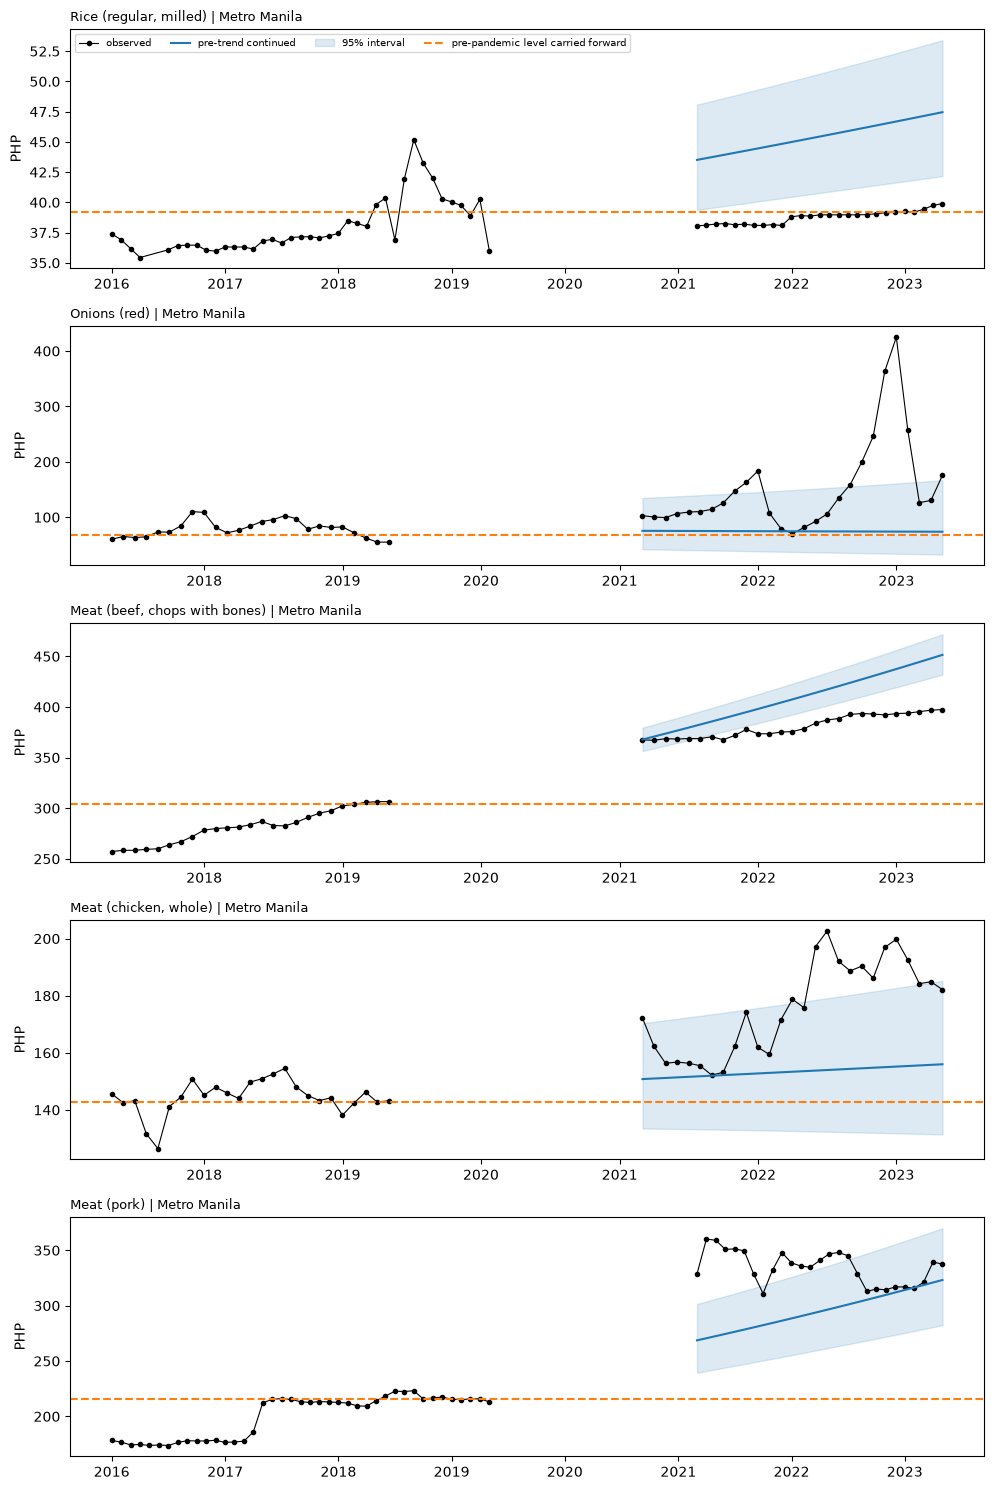

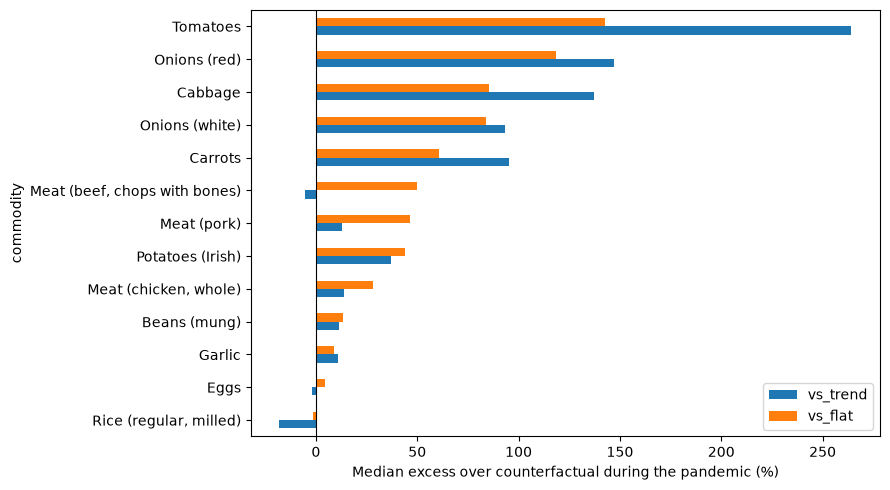

In [6]:
ex = E[(E["market"] == "Metro Manila") & (E["commodity"].isin(CORE))]
fig, axes = plt.subplots(len(ex), 1, figsize=(10, 3 * len(ex)), squeeze=False)
dt = lambda tt: pd.to_datetime("2016-01-01") + pd.to_timedelta(np.asarray(tt) * 30.4375, unit="D")
for ax, r in zip(axes[:, 0], ex.itertuples(index=False)):
    s = d[(d["market_id"] == r.market_id) & (d["commodity_id"] == r.commodity_id)]
    t, y, tn, yo, pred, half, flat = counterfactual(s)
    ax.plot(dt(t), np.exp(y), "k.-", lw=0.8, label="observed"); ax.plot(dt(tn), np.exp(yo), "k.-", lw=0.8)
    ax.plot(dt(tn), np.exp(pred), color="tab:blue", label="pre-trend continued")
    ax.fill_between(dt(tn), np.exp(pred - half), np.exp(pred + half), color="tab:blue", alpha=0.15, label="95% interval")
    ax.axhline(np.exp(flat), color="tab:orange", ls="--", label="pre-pandemic level carried forward")
    ax.set_title(f"{r.commodity} | {r.market}", fontsize=9, loc="left"); ax.set_ylabel("PHP")
axes[0, 0].legend(fontsize=7, ncol=4)
plt.tight_layout(); plt.savefig(FIG / "14_counterfactual_examples.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
bc[["vs_trend", "vs_flat"]].plot(kind="barh", ax=ax); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Median excess over counterfactual during the pandemic (%)")
plt.tight_layout(); plt.savefig(FIG / "14_excess_by_commodity.png", dpi=150); plt.show()

In [7]:
C.to_csv(TAB / "14_counterfactual_observations.csv", index=False)
w.to_csv(TAB / "14_excess_by_series.csv", index=False)
bc.to_csv(TAB / "14_excess_by_commodity.csv"); bm.to_csv(TAB / "14_excess_by_market.csv")
B.to_csv(TAB / "14_break_tests.csv", index=False)
print("saved")

saved
